Vom face transformarea fisierului CSV intr-un tabel Python, pentru a putea fi procesat; se va face si citirea numarului de randuri si coloane si vom afisa primele 5 randuri. Coloane pe care trebuie sa o prezicem este cea de Churn.


In [1]:
# Proiectul 1 - Predictia plecarii clientilor (Telco Churn)

# incarcare fisier
import pandas as pd

url = "https://raw.githubusercontent.com/valentindragomir000-ai/proiect-1-ml/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Explorarea si Intelegerea Datelor

Tasks: dimensiunea, valorile lipsa, distributia tintei si 3 grafice.

In [2]:
## 1. Explorarea datelor

# Dimensiunea si tipul coloanelor = 7043 / 21
print(df.shape)
df.info()


(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [3]:
# Valori lipsa = 11
df.isna().sum()
(df["TotalCharges"] == " ").sum()

np.int64(11)

In [4]:
# Distributia tintei (cati clienti  au da/nu si sunt arate sub forma de proportii)
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True)

,proportion
Churn,
No,0.73463
Yes,0.26537


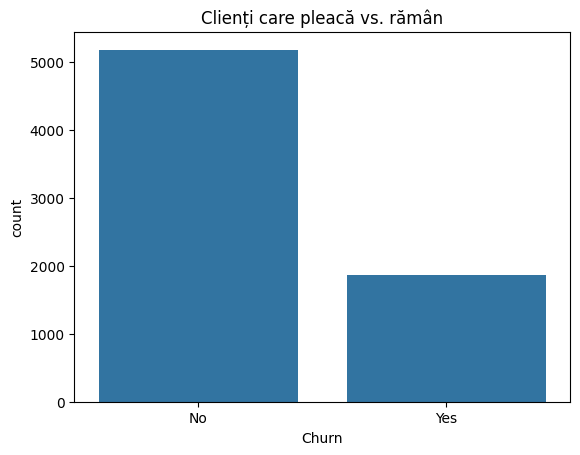

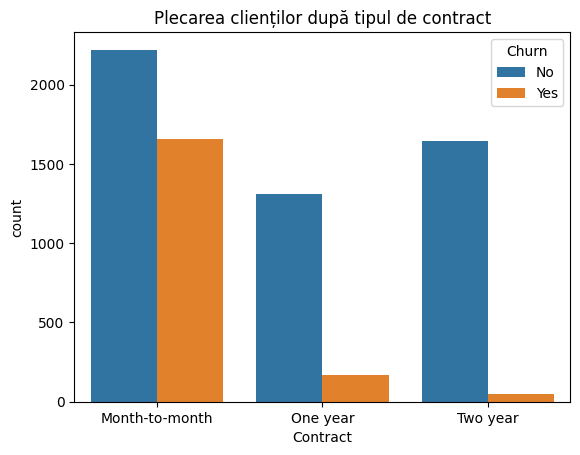

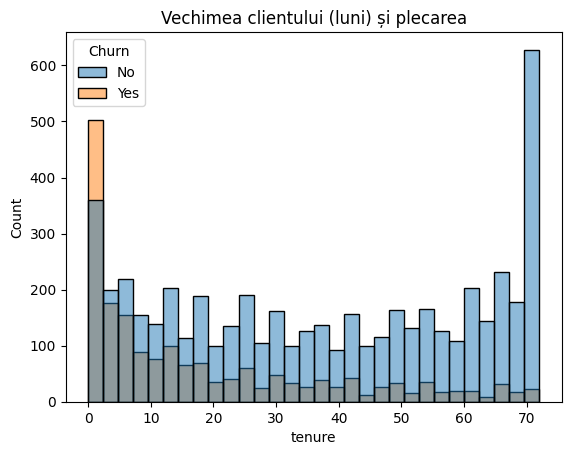

In [5]:
# Cele 3 grafice

# importare date
import matplotlib.pyplot as plt
import seaborn as sns

# Grafic 1 : cati clienti pleaca
sns.countplot(data=df, x="Churn")
plt.title("Clienți care pleacă vs. rămân")
plt.show()

# Grafic 2 : tipul de contract vs. plecare
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Plecarea clienților după tipul de contract")
plt.show()

# Grafic 3 : vechimea clientului vs. plecare
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Vechimea clientului (luni) și plecarea")
plt.show()

Curatarea datelor


In [6]:
## 2. Curatarea si pregatirea datelor
# transformare text in numar
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isna().sum()

# cele 11 lipsuri
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

# zero in locul valorilor lipsa
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# scoatem customerId
df = df.drop(columns=["customerID"])

# tinta -> 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df["Churn"].value_counts()

# verificare
df.info()

# total charge de tip float64 si churn de tip int64 si 20 de coloane pentru ca am renuntat la customerId

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


Pregatirea pentru model

In [7]:
## Pregatirea pentru model

# separare linii tinta
X = df.drop(columns=["Churn"])
y = df["Churn"]


# transformare coloane text in coloane 0 si 1
X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.shape)
X.head()


# impartirea train/test; 80%-20%
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)


# scalare ; necesara pentru ca avem coloane cu numere mari (TotalCharges); fit_transform / transform: scaler-ul invata doar din train.
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])



(7043, 30)
(5634, 30) (1409, 30)
